# 05 · Evaluación final, equidad y robustez

**Proyecto:** Predicción de riesgo de burnout organizacional · **Autor:** Oscar Paúl Naranjo Castro
**Maestría en Inteligencia Artificial, UEES** · Todas las rutas son relativas a la raíz del repositorio.

Se entrena el modelo final con la configuración optimizada y se evalúa **una sola vez** en el test: métricas, comparación con baselines, análisis de errores, intervalos de predicción, auditoría de equidad y pruebas de estrés.

In [1]:
%matplotlib inline
import sys, warnings
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
FIG = ROOT / "results" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

In [2]:
import json
from IPython.display import Image, display
from src.train import train
modelo = train()  # entrena, evalúa y guarda models/best_model.pkl
M = ROOT / 'results' / 'metrics'
resumen = json.load(open(M / 'final_metrics.json', encoding='utf-8'))
pd.Series(resumen['test']).round(4).to_frame('test')

13:49:15 | INFO | src.data_processing | Datos cargados: 22750 filas, 9 columnas


13:49:15 | INFO | src.data_processing | Filas con objetivo observado: 21626 (se descartaron 1124)


13:49:15 | INFO | src.data_processing | Dataset procesado guardado en /home/claude/prediccion-burnout-organizacional/data/processed/burnout_clean.csv


13:49:15 | INFO | src.train | Partición estratificada: 17300 train / 4326 test


13:49:15 | INFO | src.train | model_v1.pkl guardado


13:49:18 | INFO | src.train | Corte de alerta calibrado con validación cruzada: 0.580


13:49:25 | INFO | src.evaluate | Test | corte 0.580 | RMSE 0.0582 | MAE 0.0462 | R2 0.9140 | Sensibilidad 0.864


13:49:33 | INFO | src.evaluate | Reporte guardado en /home/claude/prediccion-burnout-organizacional/results/reports/reporte_evaluacion.md


13:49:33 | INFO | src.train | best_model.pkl guardado | RMSE test 0.0582 | R2 0.9140


,test
rmse,0.0582
mae,0.0462
r2,0.9140
sensibilidad,0.8642
especificidad,0.9229
precision,0.7782
f1,0.8189
tasa_alerta_real,0.2383
tasa_alerta_predicha,0.2647
auc_roc,0.9700


## 1. Comparación con baselines (test)

,rmse,mae,r2,sensibilidad,precision,f1,auc_roc
modelo,,,,,,,
Media (sin modelo),0.1986,0.1595,-0.0001,0.0000,0.0000,0.0000,0.5000
Solo fatiga (lineal),0.0871,0.0633,0.8075,0.6877,0.8501,0.7603,0.9399
Ridge,0.0703,0.0526,0.8748,0.7401,0.8249,0.7802,0.9610
SVR-RBF,0.0588,0.0463,0.9124,0.7944,0.8366,0.8149,0.9694
XGBoost v1 (por defecto),0.0601,0.0472,0.9085,0.7895,0.8264,0.8075,0.9672
XGBoost final (optimizado),0.0582,0.0462,0.9140,0.7905,0.8385,0.8138,0.9700
XGBoost final + corte calibrado (0.580),0.0582,0.0462,0.9140,0.8642,0.7782,0.8189,0.9700


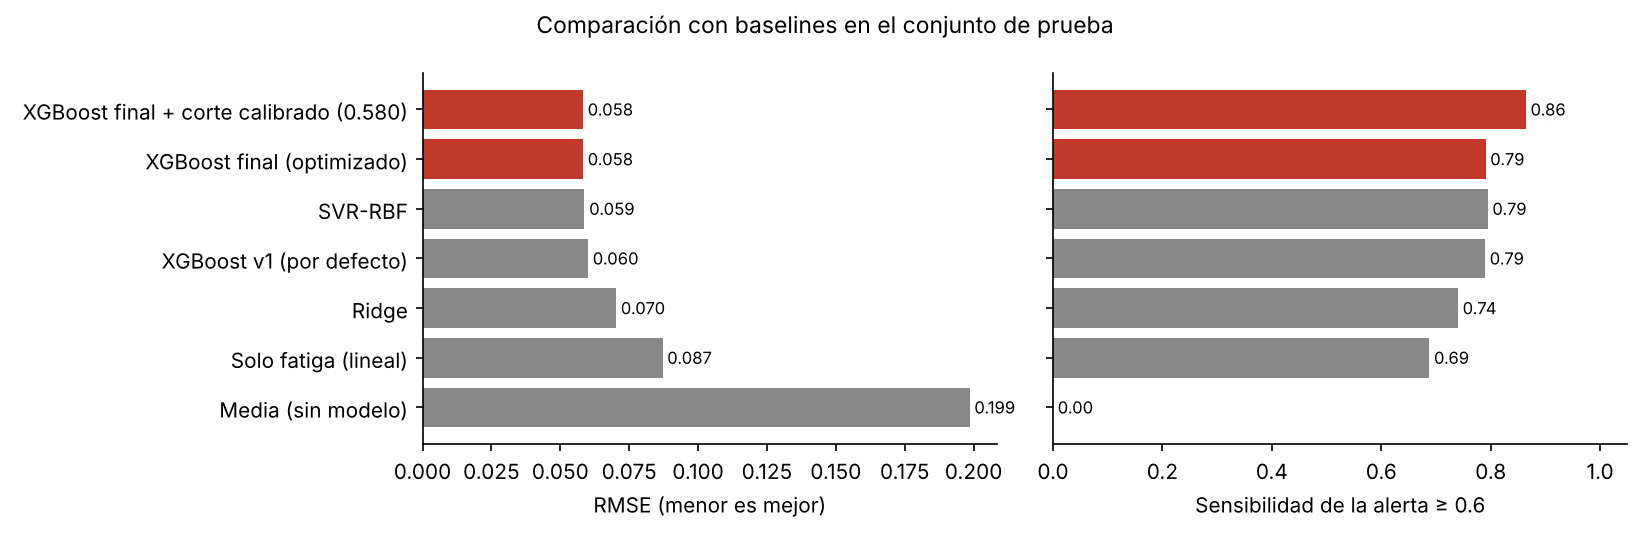

In [3]:
display(pd.read_csv(M / 'model_comparison.csv', index_col=0)[['rmse', 'mae', 'r2', 'sensibilidad', 'precision', 'f1', 'auc_roc']])
display(Image(FIG / 'model_comparison.png'))

Todas las filas usan el mismo criterio (alerta si la predicción es ≥ 0.6), salvo la última, que aplica al mismo
modelo final el corte de alerta calibrado en entrenamiento. El modelo final reduce el RMSE del baseline de una variable de
0.087 a 0.058 (33 % menos). Frente a XGBoost por defecto la ganancia es menor, coherente con lo observado en la optimización.
Con el corte calibrado la sensibilidad sube de 0.79 a 0.86 manteniendo la precisión en 0.78, de modo que se cumplen las
cuatro metas planificadas: RMSE ≤ 0.10, R² ≥ 0.75, sensibilidad ≥ 85 % y precisión ≥ 70 %.

## 2. Análisis de errores

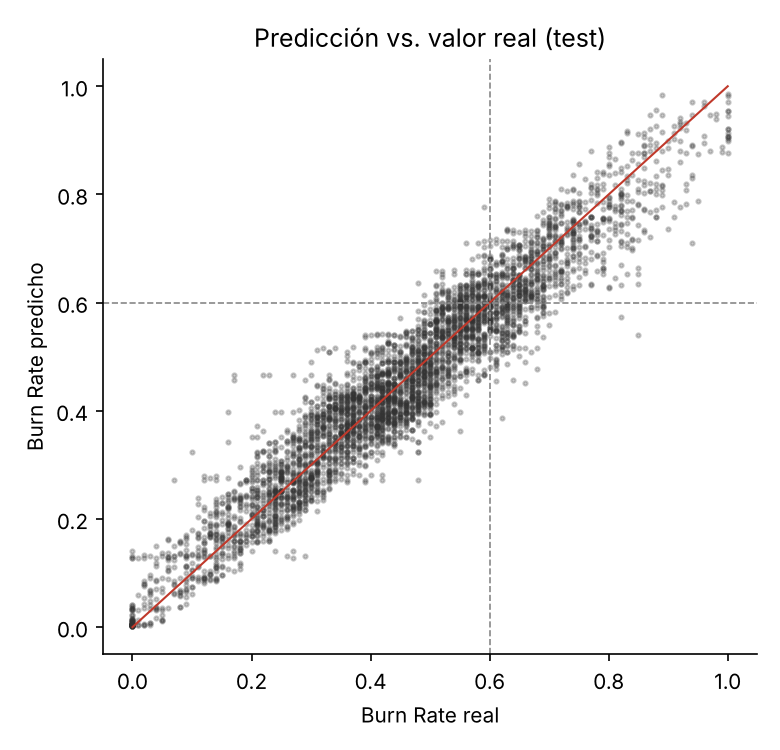

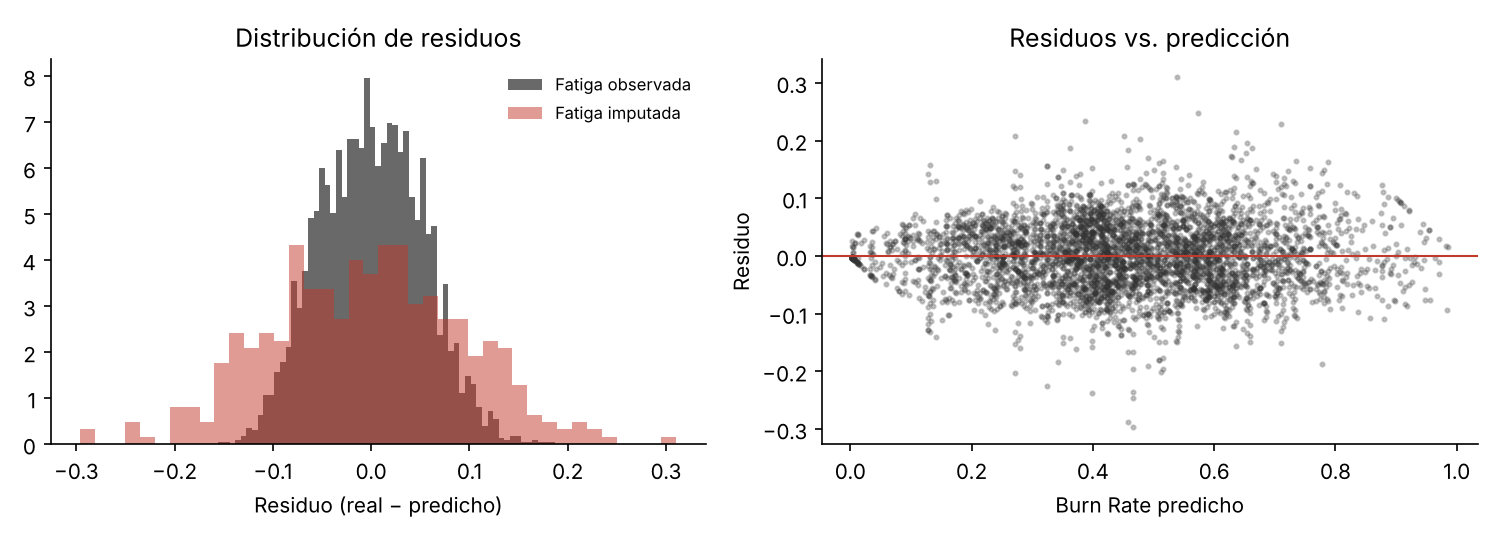

,n,rmse,mae,tasa_alerta_predicha,sensibilidad
grupo,,,,,
"[0.0, 0.2)",421,0.0572,0.0415,0.0000,NaN
"[0.2, 0.4)",1238,0.0570,0.0454,0.0000,NaN
"[0.4, 0.6)",1636,0.0543,0.0443,0.1553,NaN
"[0.6, 0.8)",828,0.0601,0.0485,0.8333,0.8333
"[0.8, 1.0)",203,0.0851,0.0673,0.9901,0.9901


In [4]:
display(Image(FIG / 'pred_vs_real.png'))
display(Image(FIG / 'residuals.png'))
pd.read_csv(M / 'error_by_target_range.csv', index_col=0)[['n', 'rmse', 'mae', 'tasa_alerta_predicha', 'sensibilidad']]

**Dónde funciona bien y dónde no.** El error es estable en el rango 0 a 0.8 (MAE ≈ 0.045), pero aumenta en los casos
extremos (≥ 0.8, MAE ≈ 0.067) porque el modelo tiende a contraer las predicciones hacia el centro. El mayor error ocurre
cuando falta la fatiga mental: el RMSE casi se duplica.

## 3. Corte de alerta: compromiso sensibilidad / precisión
Riesgo alto se define como Burn Rate real ≥ 0.6. Como el modelo contrae sus predicciones hacia el centro, usar 0.6 también
como corte deja escapar casos. El corte se calibró con predicciones fuera de muestra **del conjunto de entrenamiento**
(función `select_alert_cutoff`): el valor más alto que logra al menos 85 % de sensibilidad. La tabla siguiente, sobre el
test, solo confirma el compromiso; no se usó para elegir el corte.

In [5]:
print('Corte calibrado en entrenamiento:', modelo.alert_cutoff)

Corte calibrado en entrenamiento: 0.58


In [6]:
from sklearn.metrics import f1_score, precision_score, recall_score
from src.data_processing import clean_data, load_raw_data, split_data
X_train, X_test, y_train, y_test = split_data(clean_data(load_raw_data()), 0.2, 42)
pred = modelo.predict(X_test)
real = y_test >= 0.6
filas = []
for u in [0.50, 0.52, 0.55, 0.58, 0.60, 0.62]:
    alerta = pred >= u
    filas.append({'umbral_de_decision': u, 'sensibilidad': recall_score(real, alerta),
                  'precision': precision_score(real, alerta), 'f1': f1_score(real, alerta),
                  'tasa_alerta_predicha': alerta.mean()})
umbrales = pd.DataFrame(filas).round(3)
umbrales

13:49:33 | INFO | src.data_processing | Datos cargados: 22750 filas, 9 columnas


13:49:33 | INFO | src.data_processing | Filas con objetivo observado: 21626 (se descartaron 1124)


,umbral_de_decision,sensibilidad,precision,f1,tasa_alerta_predicha
0,0.50,0.985,0.580,0.730,0.405
1,0.52,0.966,0.625,0.759,0.368
2,0.55,0.922,0.700,0.796,0.314
3,0.58,0.864,0.778,0.819,0.265
4,0.60,0.790,0.838,0.814,0.225
5,0.62,0.713,0.899,0.795,0.189


Con el corte de 0.58 la sensibilidad en test es 0.86 y la precisión 0.78. Bajar más el corte (0.55) detecta el 92 %
de los casos pero una de cada tres alertas sería falsa. Como la alerta solo invita a una conversación voluntaria de
bienestar (nunca a una decisión sobre la persona), privilegiar la sensibilidad es coherente con el uso previsto.

## 4. Intervalos de predicción conformales

In [7]:
pd.read_csv(M / 'interval_coverage.csv', index_col=0)

,n,cobertura,ancho_medio
segmento,,,
Fatiga imputada,411.0,0.9221,0.3236
Fatiga observada,3915.0,0.9101,0.1711
Total,4326.0,0.9112,0.1856


La cobertura empírica (≈ 91 %) coincide con la nominal (90 %) en ambos segmentos, y el intervalo se ensancha de forma honesta cuando falta la fatiga.

## 5. Explicabilidad

,importancia
Mental Fatigue Score,0.794
Resource Allocation,0.178
Designation,0.021
WFH Setup Available,0.005
Company Type,0.001


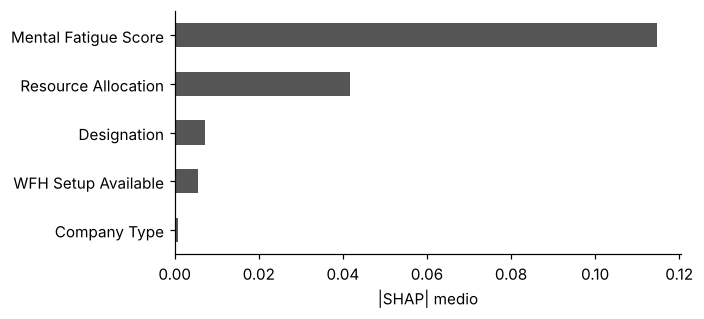

In [8]:
imp = pd.read_csv(M / 'feature_importance.csv', index_col=0)
display(imp.round(3))
contrib = modelo.explain(X_test.sample(1000, random_state=1))
shap_abs = contrib.drop(columns='base').abs().mean().sort_values()
ax = shap_abs.plot(kind='barh', color='#555', figsize=(6.5, 3)); ax.set_xlabel('|SHAP| medio')
plt.tight_layout(); plt.savefig(FIG / 'shap_global.png', dpi=150); plt.show()

## 6. Auditoría de equidad

In [9]:
for g in ['gender', 'fatigue', 'designation', 'wfh']:
    print('==', g); display(pd.read_csv(M / f'group_metrics_{g}.csv', index_col=0).round(3))
pd.DataFrame(resumen['equidad']).T.round(3)

== gender


,rmse,mae,r2,n,tasa_alerta_real,tasa_alerta_predicha,sensibilidad,falsos_positivos
grupo,,,,,,,,
Female,0.058,0.046,0.910,2269,0.181,0.212,0.895,0.061
Male,0.059,0.047,0.914,2057,0.302,0.323,0.844,0.098


== fatigue


,rmse,mae,r2,n,tasa_alerta_real,tasa_alerta_predicha,sensibilidad,falsos_positivos
grupo,,,,,,,,
Fatiga imputada,0.098,0.080,0.765,411,0.243,0.282,0.790,0.119
Fatiga observada,0.052,0.043,0.930,3915,0.238,0.263,0.872,0.073


== designation


,rmse,mae,r2,n,tasa_alerta_real,tasa_alerta_predicha,sensibilidad,falsos_positivos
grupo,,,,,,,,
0,0.046,0.036,0.782,284,0.000,0.000,NaN,0.000
1,0.054,0.043,0.825,918,0.000,0.000,NaN,0.000
2,0.059,0.047,0.830,1455,0.141,0.153,0.702,0.063
3,0.062,0.049,0.792,1135,0.344,0.366,0.811,0.133
4,0.061,0.050,0.690,458,0.784,0.939,0.986,0.768
5,0.057,0.047,0.492,76,1.000,1.000,1.000,0.000


== wfh


,rmse,mae,r2,n,tasa_alerta_real,tasa_alerta_predicha,sensibilidad,falsos_positivos
grupo,,,,,,,,
Con teletrabajo,0.057,0.046,0.905,2389,0.145,0.155,0.847,0.038
Sin teletrabajo,0.060,0.047,0.909,1937,0.354,0.400,0.873,0.141


,brecha_mae,brecha_rmse,brecha_sensibilidad,brecha_tasa_alerta_predicha,brecha_falsos_positivos,dpd_alerta,eod_alerta
gender,0.001,0.001,0.051,0.111,0.036,0.111,0.051
fatigue,0.037,0.046,0.082,0.019,0.046,0.019,0.082
designation,0.014,0.016,0.298,1.000,0.768,1.000,1.000
company,0.001,0.001,0.010,0.019,0.001,0.019,0.010
wfh,0.001,0.003,0.026,0.244,0.102,0.244,0.102


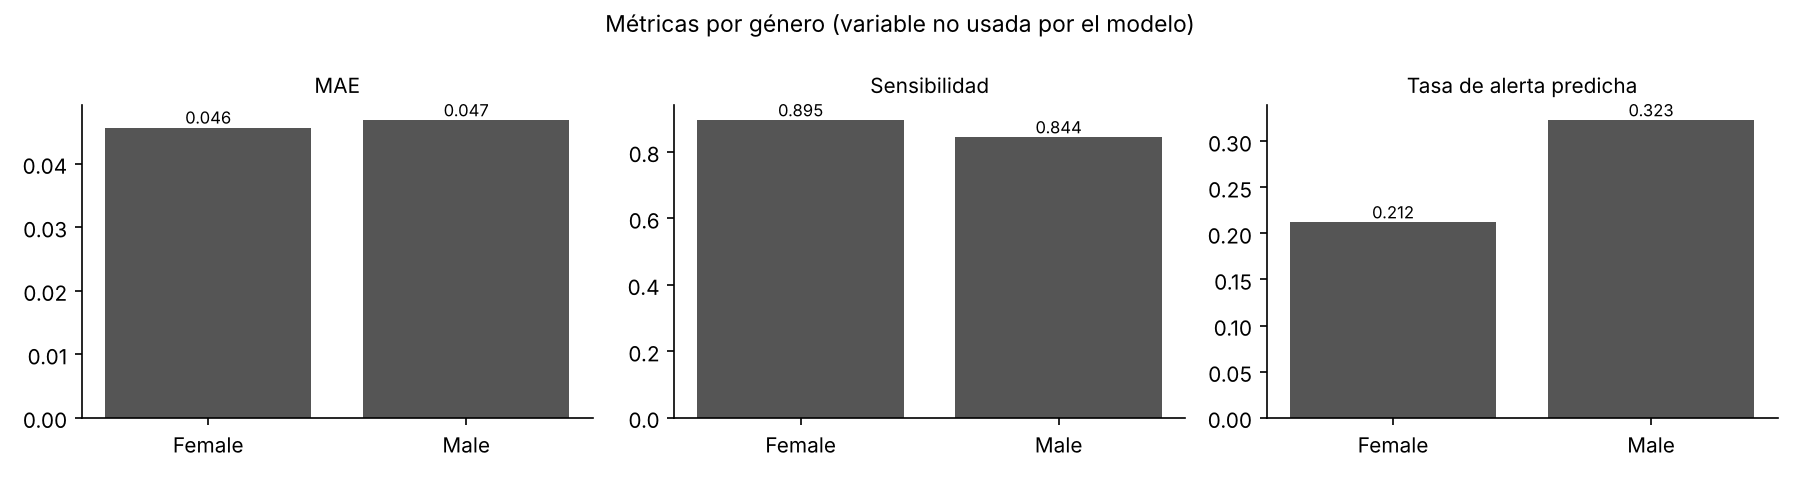

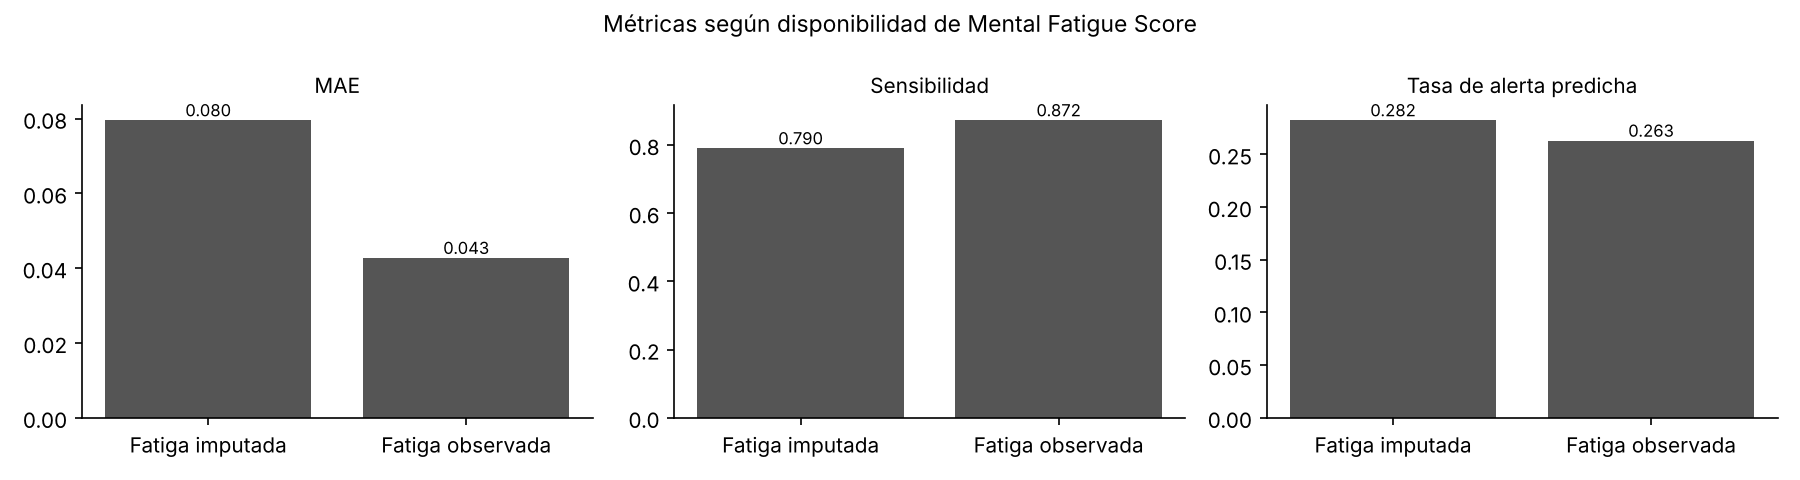

,rmse,mae,sensibilidad
variante,,,
Con Gender,0.0582,0.0462,0.7963
Sin Gender (final),0.0582,0.0462,0.7905


In [10]:
display(Image(FIG / 'fairness_gender.png'))
display(Image(FIG / 'fairness_fatigue.png'))
pd.read_csv(M / 'ablation_gender.csv', index_col=0)[['rmse', 'mae', 'sensibilidad']]

**Lectura.**
* **Género:** el error es prácticamente igual (brecha de MAE 0.001). Con el corte calibrado la sensibilidad es 0.90 en
  mujeres y 0.84 en hombres, y la tasa de falsas alarmas 6 % frente a 10 %: una brecha moderada que se documenta y se
  vigila. La diferencia en tasa de alertas (≈ 11 puntos) reproduce la diferencia real en los datos (30 % vs 18 % de
  riesgo alto). Incluir *Gender* no mejora el modelo, así que se excluye.
* **Fatiga faltante:** es el grupo más perjudicado (RMSE 0.098 vs 0.052; sensibilidad 0.79 vs 0.87). Mitigaciones:
  indicador de faltante, intervalos más anchos y aviso en la interfaz.
* **Designation:** las diferencias de tasa de alerta reflejan tasas base muy distintas (0 % en niveles 0 y 1);
  la sensibilidad más baja está en el nivel 2 (≈ 0.70), donde los casos de riesgo alto están cerca del umbral, y el
  nivel 4 concentra falsas alarmas porque casi todos sus integrantes están cerca o por encima de 0.6.

## 7. Pruebas de estrés (simulación de escenarios críticos)

,escenario,nivel,rmse,sensibilidad,precision,f1
0,Sin perturbar,-,0.058,0.864,0.778,0.819
1,Ruido en entradas,σ=0.1,0.065,0.809,0.818,0.813
2,Ruido en entradas,σ=0.25,0.074,0.791,0.795,0.793
3,Ruido en entradas,σ=0.5,0.101,0.754,0.707,0.730
4,Ruido en entradas,σ=1.0,0.168,0.693,0.547,0.611
5,Datos faltantes,10%,0.065,0.846,0.773,0.808
6,Datos faltantes,30%,0.079,0.794,0.763,0.778
7,Datos faltantes,50%,0.094,0.729,0.749,0.739
8,Fatiga no disponible,100%,0.101,0.733,0.696,0.714
9,Cambio de prevalencia,10% riesgo alto,0.057,0.864,0.552,0.673


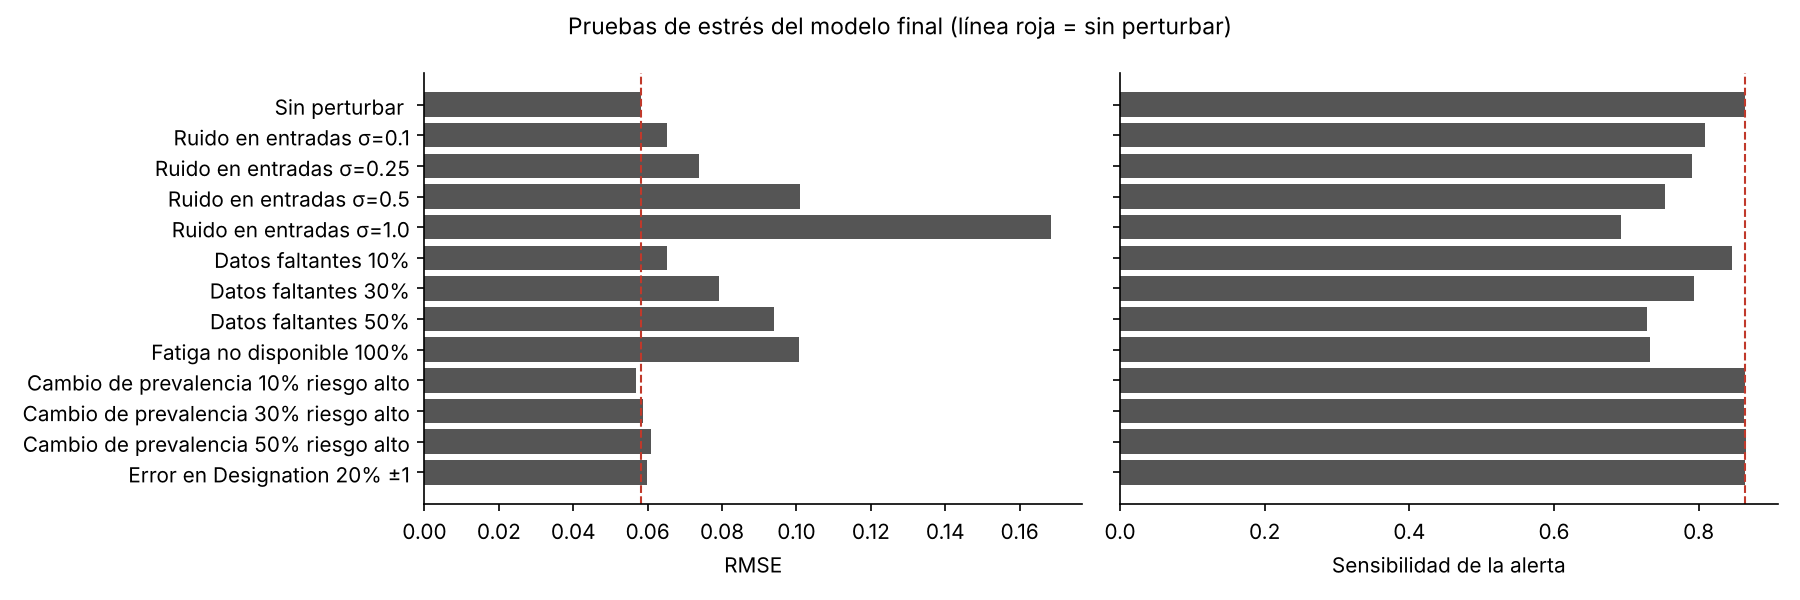

,rmse,r2,sensibilidad
evaluado_en,,,
Company Type = Service (mismo grupo),0.059,0.908,0.776
Company Type ≠ Service (grupo distinto),0.060,0.910,0.764


In [11]:
display(pd.read_csv(M / 'stress_tests.csv')[['escenario', 'nivel', 'rmse', 'sensibilidad', 'precision', 'f1']].round(3))
display(Image(FIG / 'stress_tests.png'))
pd.read_csv(M / 'distribution_shift.csv', index_col=0)[['rmse', 'r2', 'sensibilidad']].round(3)

**Criterio de aceptación definido antes de mirar resultados:** caída máxima de 5 puntos de sensibilidad.
* Cumplen: datos faltantes hasta 10 % (−1.8 puntos), cambios de prevalencia, error de captura en Designation y cambio de
  tipo de empresa.
* No cumplen: ruido en entradas desde σ = 0.1 (−5.5 puntos), faltantes del 30 % o más y la pérdida total de la fatiga.
* La precisión cae cuando la prevalencia real es baja (0.55 con 10 % de casos): en una organización con poco burnout,
  casi la mitad de las alertas serían falsas, lo que refuerza su uso solo como invitación voluntaria.

**Implicación para producción:** el sistema depende de una medición de fatiga confiable y completa. Se recomienda
monitorear la tasa de faltantes y la distribución de la fatiga, y revalidar el modelo si cambian.